In [1]:
import pandas as pd
import matplotlib.pyplot as plt

train_df = pd.read_csv("../data/raw/Train_data.csv")
test_df = pd.read_csv("../data/raw/Test_data.csv")

print(train_df.shape)
print(test_df.shape)
train_df.head()

(25192, 42)
(22544, 41)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,class
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,25,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal
1,0,udp,other,SF,146,0,0,0,0,0,...,1,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal
2,0,tcp,private,S0,0,0,0,0,0,0,...,26,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,anomaly
3,0,tcp,http,SF,232,8153,0,0,0,0,...,255,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal
4,0,tcp,http,SF,199,420,0,0,0,0,...,255,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal


In [2]:
print(train_df.columns.tolist())
print(train_df.isnull().sum().sort_values(ascending=False).head(20))

['duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login', 'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate', 'class']
duration                       0
dst_host_count                 0
srv_count                      0
serror_rate                    0
srv_serror_rate                0
rerror_rate                    0
srv_rerror_rate                0
same_srv_rate                  

In [3]:
target_col = "class" if "class" in train_df.columns else train_df.columns[-1]
print("Target:", target_col)
print(train_df[target_col].value_counts().head(20))

Target: class
class
normal     13449
anomaly    11743
Name: count, dtype: int64


In [4]:
binary_target = train_df[target_col].apply(lambda x: "normal" if str(x).lower() == "normal" else "attack")
print(binary_target.value_counts())

class
normal    13449
attack    11743
Name: count, dtype: int64


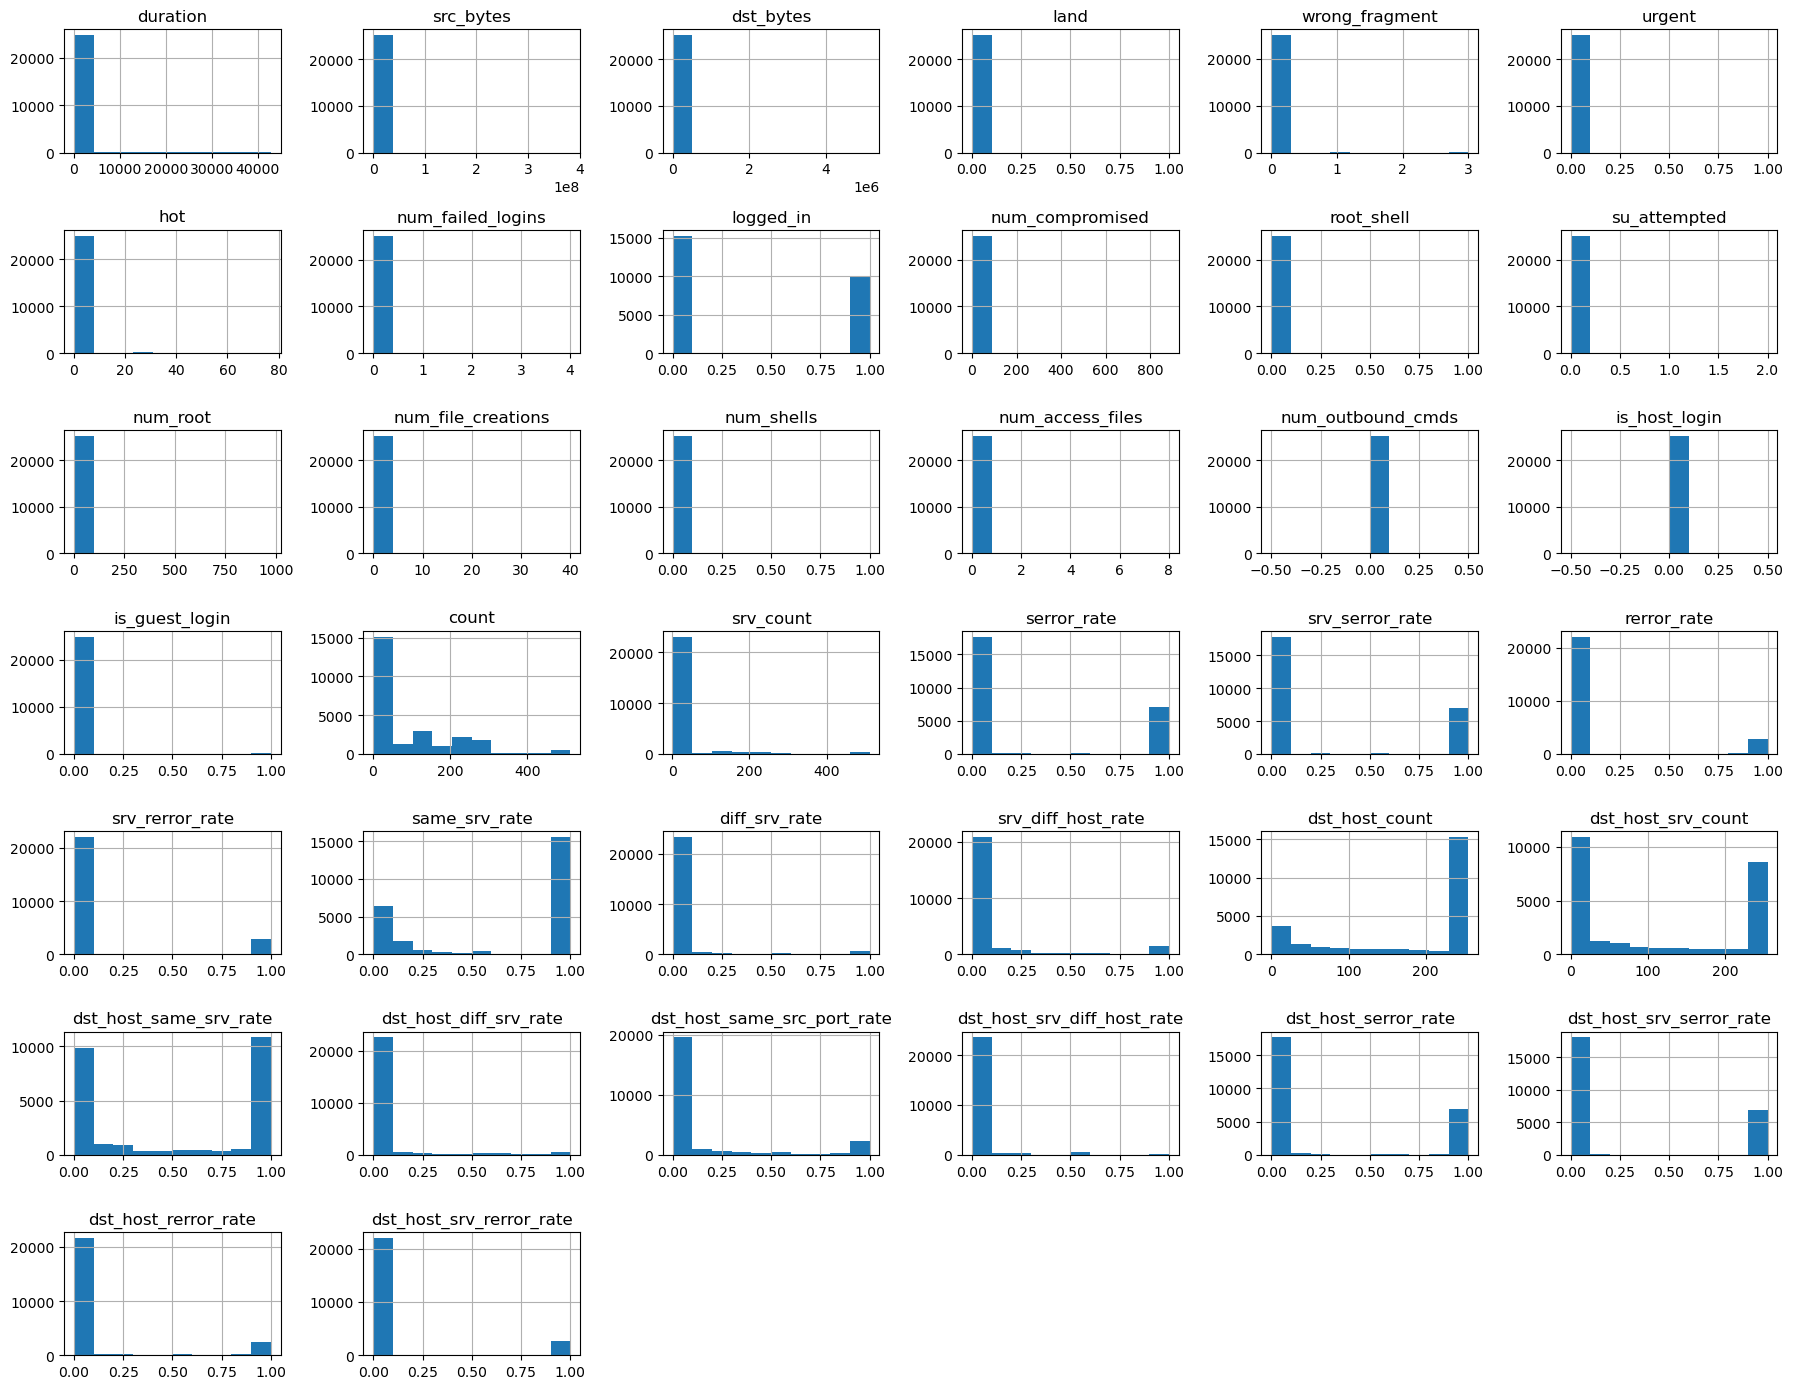

In [5]:
numeric_cols = train_df.select_dtypes(include=["int64", "float64"]).columns.tolist()
train_df[numeric_cols].hist(figsize=(18, 14))
plt.tight_layout()
plt.show()

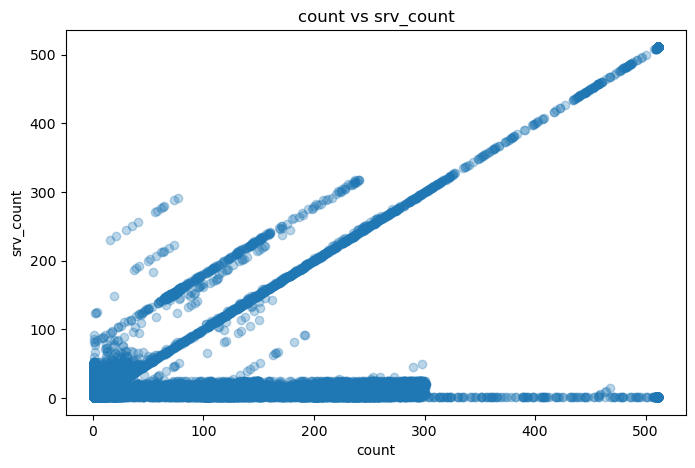

In [6]:
if "count" in train_df.columns and "srv_count" in train_df.columns:
    plt.figure(figsize=(8, 5))
    plt.scatter(train_df["count"], train_df["srv_count"], alpha=0.3)
    plt.xlabel("count")
    plt.ylabel("srv_count")
    plt.title("count vs srv_count")
    plt.show()

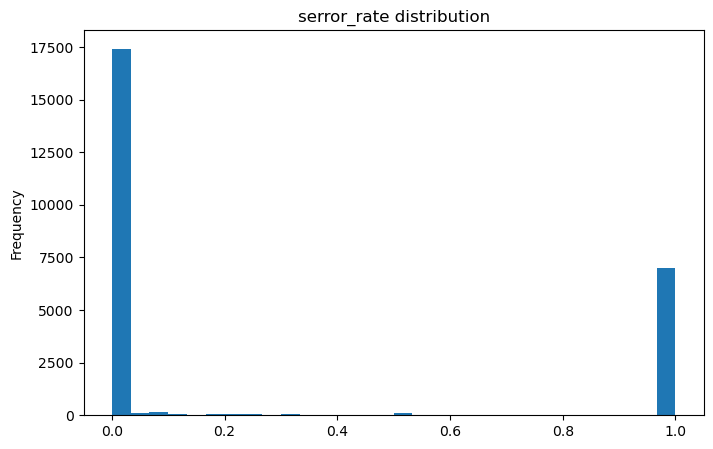

In [7]:
if "serror_rate" in train_df.columns:
    train_df["serror_rate"].plot(kind="hist", bins=30, figsize=(8, 5), title="serror_rate distribution")
    plt.show()

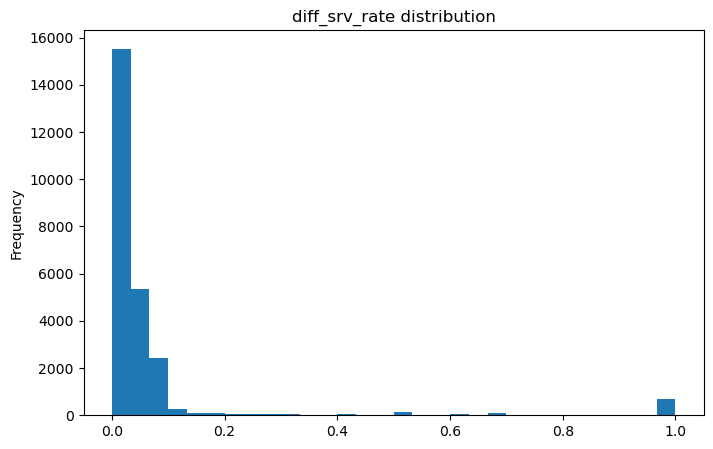

In [8]:
if "diff_srv_rate" in train_df.columns:
    train_df["diff_srv_rate"].plot(kind="hist", bins=30, figsize=(8, 5), title="diff_srv_rate distribution")
    plt.show()